# Effect of symbolic substitution and two-decimal rounding

This notebook reads the saved KAAM experiment and compares the original spline model, the symbolically substituted model and its formula rounded to **two decimal places**. Each comparison uses the same trained model and the same test observations. It does not train models or modify results. Only open pickle files from trusted sources.

Training size is 1,000 for Heart, Diabetes-H, Diabetes-130, Obesity and Obesity-Bin, and 455 for Breast Cancer. The training set includes internal validation; test is held out.

In [1]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATASETS = ['heart', 'diabetes_h', 'diabetes_130', 'obesity', 'obesity_bin', 'breast_cancer']
DATASET_LABELS = {'heart': 'Heart', 'diabetes_h': 'Diabetes-H', 'diabetes_130': 'Diabetes-130',
                  'obesity': 'Obesity', 'obesity_bin': 'Obesity-Bin', 'breast_cancer': 'Breast Cancer'}
VARIANTS = {'original': 'Original', 'formula': 'Formula', 'formula_2dec': 'Formula + 2 decimals'}
COLORS = {'original': '#0072B2', 'formula': '#D55E00', 'formula_2dec': '#009E73'}
MAIN_METRICS = {'Accuracy': 'accuracy', 'ROC-AUC': 'roc_auc', 'F1': 'f1', 'Precision': 'precision', 'Recall': 'recall'}
APPENDIX_METRICS = {'ECE': 'ece', 'Brier score': 'brier', 'Log loss': 'log_loss',
                    'Macro-F1 (multiclass)': 'f1_macro', 'Balanced accuracy (multiclass)': 'balanced_accuracy'}
DECIMALS = 3

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'src' / 'symbolic_experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook within the project directory.')
RESULTS_DIR = ROOT / 'results_symbolic'
print(f'Reading results from: {RESULTS_DIR}')

Reading results from: C:\Users\Alex\CODE\classification_with_kans\results_symbolic


## Coverage and checks

The script compares the extracted symbolic formula with the symbolified model before rounding. The table reports the maximum difference between their logits, the number of valid paired bootstrap samples, and whether the saved experimental split was checked against the main KAAM result. A missing or incompatible file is reported instead of silently plotted.

In [2]:
results, problems, coverage = {}, [], []
for dataset in DATASETS:
    path = RESULTS_DIR / f'{dataset}.pkl'
    try:
        with path.open('rb') as file:
            result = pickle.load(file)
        expected_size = 455 if dataset == 'breast_cancer' else 1000
        if not isinstance(result, dict) or result.get('dataset') != dataset or result.get('train_size') != expected_size:
            raise ValueError('Dataset or training size does not match')
        if result.get('round_decimals') != 2:
            raise ValueError('Result does not use two-decimal rounding')
        if result.get('bootstrap', {}).get('ci') != 95 or result['bootstrap'].get('method') != 'percentile':
            raise ValueError('95% percentile bootstrap results are missing')
        if any(name not in result['variants'] for name in VARIANTS):
            raise ValueError('A model variant is missing')
        results[dataset] = result
        boot = result['bootstrap']
        coverage.append({'Dataset': DATASET_LABELS[dataset], 'Training size': result['train_size'],
                         'Valid bootstrap': f"{boot['n_valid']}/{boot['n_bootstrap']}",
                         'Max formula logit error': result['formula_max_logit_error'],
                         'Main split checked': result['reference_split_checked']})
    except Exception as exc:
        problems.append({'Dataset': DATASET_LABELS[dataset], 'File': str(path), 'Issue': str(exc)})

if coverage:
    display(pd.DataFrame(coverage))
if problems:
    display(pd.DataFrame(problems))
if not results:
    print('No completed symbolic experiment results found. Run src/symbolic_experiment.py first.')

,Dataset,Training size,Valid bootstrap,Max formula logit error,Main split checked
0,Heart,1000,1000/1000,5.197839e-07,True
1,Diabetes-H,1000,1000/1000,3.889850e-07,True
2,Obesity,1000,1000/1000,8.080576e-05,True
3,Obesity-Bin,1000,1000/1000,4.341320e-06,True
4,Breast Cancer,455,1000/1000,2.159949e-06,True


,Dataset,File,Issue
0,Diabetes-130,C:\Users\Alex\CODE\classification_with_kans\re...,[Errno 2] No such file or directory: 'C:\\User...


## Interpreting the results

Each estimate is the mean of valid bootstrap replicates; intervals are the 2.5th and 97.5th percentiles. The same resampled test rows are used for all variants, without retraining. Resamples missing a class are excluded for all three. These intervals quantify test-resampling variability conditional on one trained model and one split, not variation between training runs.

Accuracy, ROC-AUC, F1, precision, recall, macro-F1 and balanced accuracy are better when higher. ECE, Brier score and log loss are better when lower. Binary ECE uses the positive class; multiclass ECE is macro-averaged across classes. Binary and multiclass Brier use different conventions and should not be compared across task types. Brier and log loss are not measures of calibration alone.

In [3]:
def metric_key(label, key, result):
    if label == 'ECE' and len(result['classes']) > 2:
        return 'ece_macro'
    return key


def cell(mean, interval):
    if mean is None or interval is None:
        return 'N/A'
    lo, hi = interval
    return f'{mean:.{DECIMALS}f} ({lo:.{DECIMALS}f}–{hi:.{DECIMALS}f})'


def make_summary(metrics):
    rows = []
    for dataset, result in results.items():
        for variant, name in VARIANTS.items():
            record = {'Dataset': DATASET_LABELS[dataset], 'Training size': result['train_size'], 'Variant': name}
            values = result['variants'][variant]
            for label, key in metrics.items():
                key = metric_key(label, key, result)
                record[label] = cell(values['metric_mean'].get(key), values['metric_ci'].get(key))
            rows.append(record)
    return pd.DataFrame(rows)


def plot_metrics(metrics, title):
    if not results:
        print('No results available to plot.')
        return
    plt.rcParams.update({'font.size': 12, 'axes.titlesize': 13, 'axes.labelsize': 12,
                         'xtick.labelsize': 10, 'ytick.labelsize': 11, 'legend.fontsize': 11})
    fig, axes = plt.subplots(1, len(metrics), figsize=(max(5 * len(metrics), 8), 5.5),
                             constrained_layout=True, squeeze=False)
    width = 0.24
    for ax, (label, base_key) in zip(axes.flat, metrics.items()):
        available = []
        for dataset in DATASETS:
            if dataset not in results:
                continue
            result = results[dataset]
            key = metric_key(label, base_key, result)
            if any(result['variants'][variant]['metric_mean'].get(key) is not None
                   and result['variants'][variant]['metric_ci'].get(key) is not None
                   for variant in VARIANTS):
                available.append(dataset)
        x = np.arange(len(available))
        for j, variant in enumerate(VARIANTS):
            for i, dataset in enumerate(available):
                result = results[dataset]
                key = metric_key(label, base_key, result)
                values = result['variants'][variant]
                mean = values['metric_mean'].get(key)
                interval = values['metric_ci'].get(key)
                if mean is None or interval is None:
                    continue
                position = x[i] + (j - 1) * width
                ax.bar(position, mean, width, color=COLORS[variant])
                lower, upper = interval
                # Draw the saved interval directly: a bootstrap mean need not lie inside its percentile CI.
                ax.vlines(position, lower, upper, colors='black', linewidth=1)
                ax.hlines([lower, upper], position - width * 0.18, position + width * 0.18, colors='black', linewidth=1)
        ax.set_title(label)
        ax.set_xticks(x, [DATASET_LABELS[d] for d in available], rotation=40, ha='right')
        ax.set_ylabel('Metric value')
        ax.grid(axis='y', alpha=0.25)
        ax.set_axisbelow(True)
    handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[v]) for v in VARIANTS]
    fig.legend(handles, list(VARIANTS.values()), loc='upper center', ncol=3, frameon=False)
    fig.suptitle(title, y=1.07)
    return fig


##### Main classification metrics — N=1,000; Breast Cancer N=455

Accuracy and ROC-AUC are reported alongside binary positive-class or multiclass support-weighted F1, precision and recall. Values are bootstrap means with 95% percentile intervals.

In [4]:
display(make_summary(MAIN_METRICS))

,Dataset,Training size,Variant,Accuracy,ROC-AUC,F1,Precision,Recall
0,Heart,1000,Original,0.759 (0.744–0.776),0.835 (0.811–0.856),0.365 (0.323–0.401),0.243 (0.211–0.272),0.736 (0.682–0.789)
1,Heart,1000,Formula,0.773 (0.756–0.790),0.823 (0.799–0.847),0.364 (0.321–0.400),0.247 (0.213–0.277),0.690 (0.629–0.749)
2,Heart,1000,Formula + 2 decimals,0.777 (0.760–0.794),0.824 (0.800–0.847),0.366 (0.323–0.403),0.250 (0.215–0.281),0.685 (0.625–0.745)
3,Diabetes-H,1000,Original,0.844 (0.830–0.858),0.762 (0.732–0.789),0.803 (0.784–0.822),0.794 (0.771–0.814),0.844 (0.830–0.858)
4,Diabetes-H,1000,Formula,0.841 (0.827–0.855),0.759 (0.726–0.789),0.771 (0.752–0.791),0.756 (0.707–0.810),0.841 (0.827–0.855)
5,Diabetes-H,1000,Formula + 2 decimals,0.841 (0.827–0.855),0.758 (0.726–0.789),0.771 (0.752–0.791),0.756 (0.707–0.810),0.841 (0.827–0.855)
6,Obesity,1000,Original,0.962 (0.943–0.979),0.997 (0.994–0.999),0.962 (0.943–0.979),0.964 (0.948–0.979),0.962 (0.943–0.979)
7,Obesity,1000,Formula,0.960 (0.941–0.976),0.997 (0.994–0.999),0.960 (0.941–0.976),0.962 (0.944–0.977),0.960 (0.941–0.976)
8,Obesity,1000,Formula + 2 decimals,0.950 (0.929–0.969),0.996 (0.992–0.998),0.950 (0.929–0.969),0.952 (0.932–0.970),0.950 (0.929–0.969)
9,Obesity-Bin,1000,Original,0.998 (0.993–1.000),1.000 (1.000–1.000),0.997 (0.992–1.000),1.000 (1.000–1.000),0.995 (0.984–1.000)


##### Figure 1 — Main classification metrics

The three bars for each dataset represent predictions from the same trained KAAM and the same held-out test rows. Vertical lines and caps are the saved 95% percentile intervals. Higher values are better.

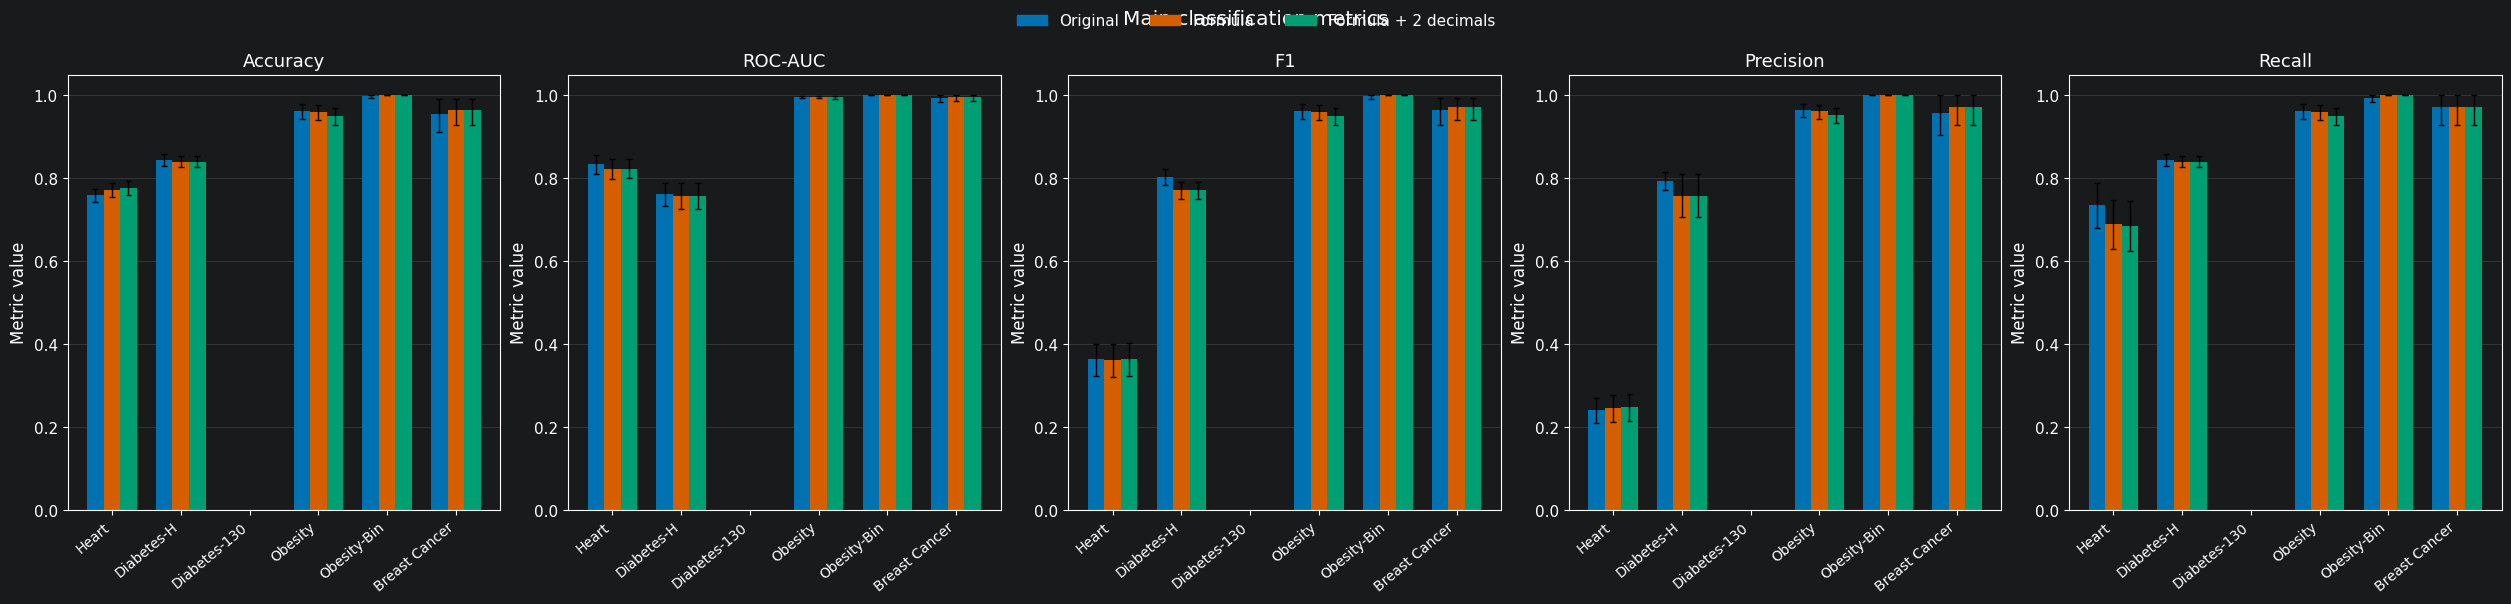

In [5]:
main_figure = plot_metrics(MAIN_METRICS, 'Main classification metrics')
plt.show()

##### Appendix metrics — calibration and multiclass classification

ECE is positive-class ECE for binary tasks and macro classwise ECE for multiclass tasks. Macro-F1 and balanced accuracy are available for multiclass datasets only. `N/A` means a metric is not defined by this experiment for that task or was not saved.

In [6]:
display(make_summary(APPENDIX_METRICS))

,Dataset,Training size,Variant,ECE,Brier score,Log loss,Macro-F1 (multiclass),Balanced accuracy (multiclass)
0,Heart,1000,Original,0.257 (0.245–0.268),0.160 (0.152–0.168),0.483 (0.464–0.503),N/A,N/A
1,Heart,1000,Formula,0.250 (0.238–0.262),0.154 (0.146–0.161),0.469 (0.452–0.487),N/A,N/A
2,Heart,1000,Formula + 2 decimals,0.246 (0.234–0.257),0.151 (0.143–0.158),0.462 (0.445–0.479),N/A,N/A
3,Diabetes-H,1000,Original,0.013 (0.008–0.019),0.231 (0.214–0.249),0.418 (0.388–0.449),0.384 (0.366–0.402),0.377 (0.365–0.390)
4,Diabetes-H,1000,Formula,0.027 (0.019–0.035),0.241 (0.222–0.261),0.433 (0.403–0.464),0.310 (0.304–0.318),0.335 (0.332–0.339)
5,Diabetes-H,1000,Formula + 2 decimals,0.028 (0.020–0.035),0.242 (0.223–0.261),0.434 (0.403–0.465),0.310 (0.304–0.318),0.335 (0.332–0.339)
6,Obesity,1000,Original,0.028 (0.024–0.032),0.084 (0.065–0.106),0.183 (0.151–0.219),0.960 (0.941–0.977),0.960 (0.941–0.977)
7,Obesity,1000,Formula,0.032 (0.028–0.036),0.086 (0.068–0.108),0.197 (0.163–0.243),0.958 (0.938–0.975),0.958 (0.939–0.976)
8,Obesity,1000,Formula + 2 decimals,0.033 (0.029–0.037),0.104 (0.085–0.126),0.217 (0.185–0.255),0.949 (0.928–0.967),0.949 (0.928–0.968)
9,Obesity-Bin,1000,Original,0.060 (0.050–0.070),0.014 (0.011–0.018),0.071 (0.059–0.083),N/A,N/A


##### Figure 2 — Appendix metrics

ECE, Brier and log loss are plotted for all tasks; macro-F1 and balanced accuracy are plotted for multiclass tasks only. Each panel uses its own vertical scale. The bars are metric values, not differences from the original.

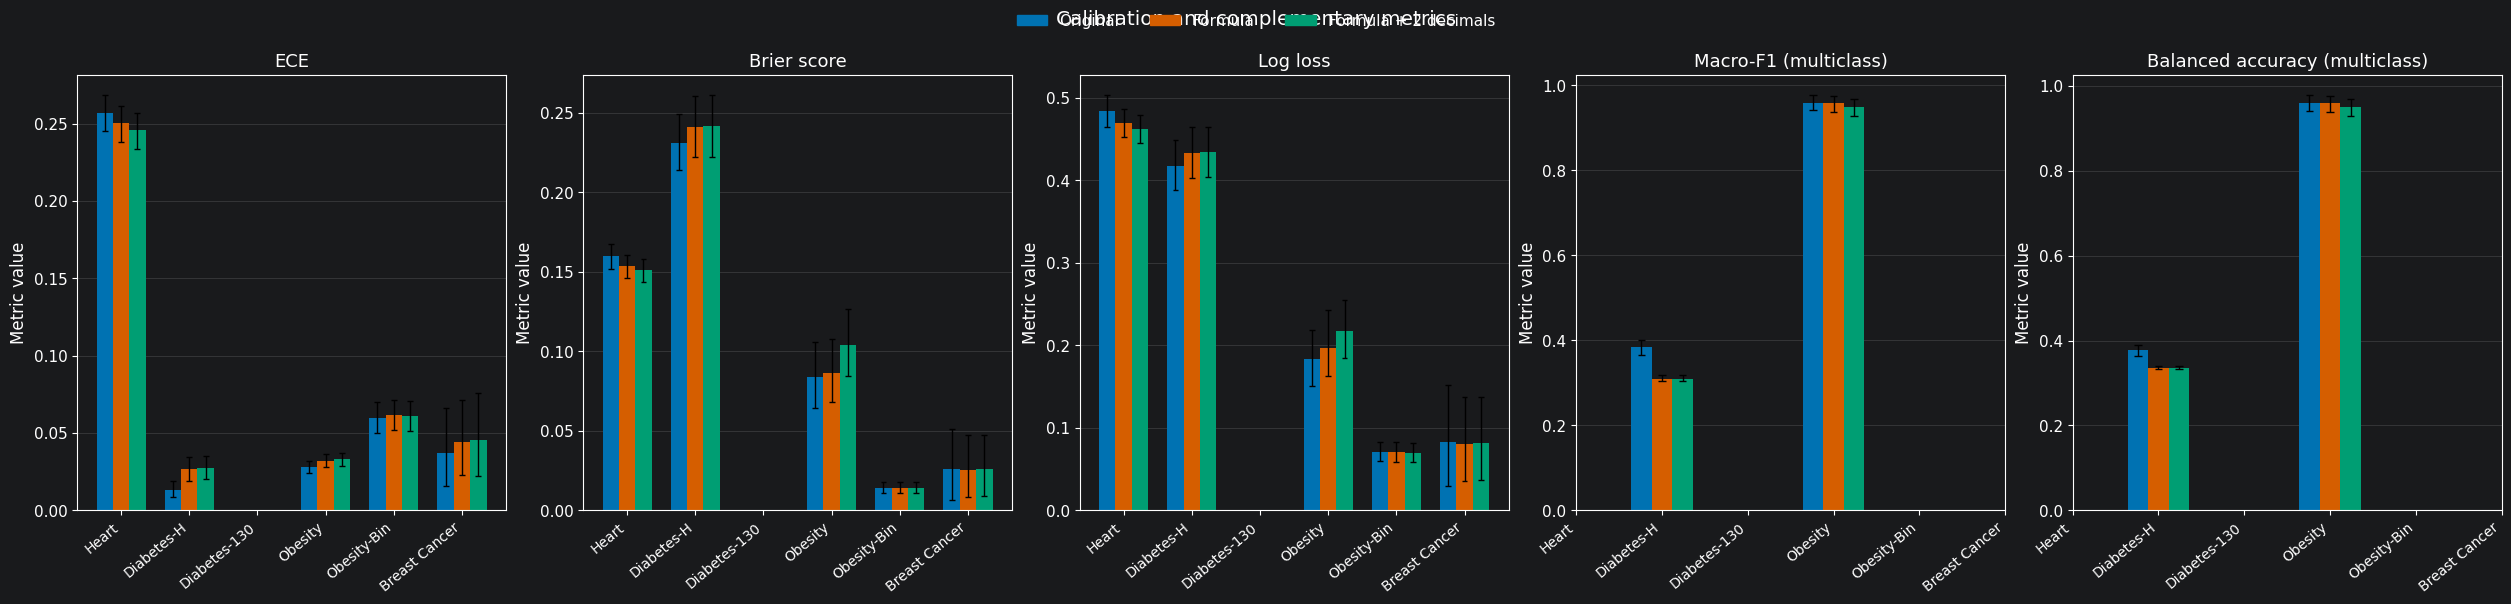

In [7]:
appendix_figure = plot_metrics(APPENDIX_METRICS, 'Calibration and complementary metrics')
plt.show()

##### Multiclass metrics by class

The class labels follow the order stored in the result. Precision, recall and ECE are shown per class, with bootstrap means and 95% intervals. These rows are separate because datasets have different numbers and meanings of classes.

In [8]:
rows = []
for dataset, result in results.items():
    classes = np.asarray(result['classes']).reshape(-1)
    if len(classes) <= 2:
        continue
    for variant, name in VARIANTS.items():
        values = result['variants'][variant]
        for i, label in enumerate(classes):
            row = {'Dataset': DATASET_LABELS[dataset], 'Variant': name, 'Class': label}
            for metric in ('precision', 'recall', 'ece'):
                key = f'{metric}_class_{i}'
                row[metric.upper() if metric == 'ece' else metric.capitalize()] = cell(values['metric_mean'].get(key), values['metric_ci'].get(key))
            rows.append(row)
display(pd.DataFrame(rows))

,Dataset,Variant,Class,Precision,Recall,ECE
0,Diabetes-H,Original,0,0.860 (0.846–0.874),0.977 (0.970–0.983),0.020 (0.010–0.029)
1,Diabetes-H,Original,1,0.000 (0.000–0.000),0.000 (0.000–0.000),0.002 (0.000–0.006)
2,Diabetes-H,Original,2,0.497 (0.404–0.591),0.155 (0.118–0.195),0.018 (0.011–0.027)
3,Diabetes-H,Formula,0,0.843 (0.829–0.856),0.997 (0.995–0.999),0.043 (0.031–0.055)
4,Diabetes-H,Formula,1,0.000 (0.000–0.000),0.000 (0.000–0.000),0.003 (0.000–0.007)
5,Diabetes-H,Formula,2,0.335 (0.000–0.692),0.009 (0.000–0.020),0.034 (0.022–0.047)
6,Diabetes-H,Formula + 2 decimals,0,0.843 (0.829–0.856),0.997 (0.995–0.999),0.045 (0.032–0.057)
7,Diabetes-H,Formula + 2 decimals,1,0.000 (0.000–0.000),0.000 (0.000–0.000),0.003 (0.000–0.007)
8,Diabetes-H,Formula + 2 decimals,2,0.335 (0.000–0.692),0.009 (0.000–0.020),0.035 (0.023–0.048)
9,Obesity,Original,0,0.947 (0.879–1.000),1.000 (1.000–1.000),0.015 (0.010–0.021)


##### Paired metric differences relative to the original

Each row is **variant minus original**, calculated within each bootstrap replicate using identical resampled test rows. The reported mean and percentile interval therefore describe the change directly; the sign must be interpreted according to whether higher or lower metric values are preferable. They do not measure retraining variability.

In [9]:
rows = []
for dataset, result in results.items():
    for variant in ('formula', 'formula_2dec'):
        for label, base_key in {**MAIN_METRICS, **APPENDIX_METRICS}.items():
            key = metric_key(label, base_key, result)
            delta = result['paired_differences'][variant].get(key)
            if delta is not None:
                rows.append({'Dataset': DATASET_LABELS[dataset], 'Variant minus original': VARIANTS[variant],
                             'Metric': label, 'Mean difference (95% CI)': cell(delta['mean'], delta['ci'])})
display(pd.DataFrame(rows))

,Dataset,Variant minus original,Metric,Mean difference (95% CI)
0,Heart,Formula,Accuracy,0.014 (0.006–0.022)
1,Heart,Formula,ROC-AUC,-0.012 (-0.018–-0.007)
2,Heart,Formula,F1,-0.001 (-0.017–0.012)
3,Heart,Formula,Precision,0.005 (-0.006–0.015)
4,Heart,Formula,Recall,-0.047 (-0.079–-0.021)
...,...,...,...,...
83,Breast Cancer,Formula + 2 decimals,Precision,0.014 (0.000–0.042)
84,Breast Cancer,Formula + 2 decimals,Recall,0.000 (0.000–0.000)
85,Breast Cancer,Formula + 2 decimals,ECE,0.009 (-0.009–0.027)
86,Breast Cancer,Formula + 2 decimals,Brier score,-0.000 (-0.006–0.006)


##### Formulas and export

The stored expressions use the transformed feature variables listed in the result, in the order shown by `symbols` and `features`. Their coefficients are therefore not automatically formulas in the original feature units. The following cell inspects their mapping and expressions. To save either figure, uncomment the corresponding `savefig` line.

In [10]:
for dataset, result in results.items():
    print(f"\n{DATASET_LABELS[dataset]}: " + ', '.join(f'{s}={f}' for s, f in zip(result['symbols'], result['features'])))
    for cls, formula, rounded in zip(result['classes'], result['formulas'], result['formulas_rounded']):
        print(f'  Class {cls}: {formula}')
        print(f'  Class {cls}, two decimals: {rounded}')

# main_figure.savefig('symbolic_main.pdf', bbox_inches='tight')
# appendix_figure.savefig('symbolic_appendix.pdf', bbox_inches='tight')


Heart: x_1=HighBP, x_2=HighChol, x_3=CholCheck, x_4=BMI, x_5=Smoker, x_6=Stroke, x_7=Diabetes, x_8=PhysActivity, x_9=Fruits, x_10=Veggies, x_11=HvyAlcoholConsump, x_12=AnyHealthcare, x_13=NoDocbcCost, x_14=GenHlth, x_15=MentHlth, x_16=PhysHlth, x_17=DiffWalk, x_18=Sex, x_19=Age, x_20=Education, x_21=Income
  Class 0: -0.262985870360154*x_1 - 0.0602758873162745*x_10 - 0.0556620836300667*x_12 + 0.0449024151324053*x_13 - 0.312434410913745*x_18 - 0.220622404907258*x_19 - 0.140139533954102*x_2 - 0.0225047065214381*x_3 - 0.149240199217807*x_4 - 0.113625995582211*x_5 - 0.0465538222754414*x_6 - 0.0161068864607772*x_8 - 0.0954396575689316*sqrt(7.51183986663818 - 5.93160009384155*x_20) - 0.000143101351568475*(9.99736022949219 - 9.60000038146973*x_7)**2 + 0.272247463464737*sin(0.634479880332947*x_16 + 8.57159996032715) - 0.526600897312164*cos(5.83128023147583*x_14 - 7.19783973693848) + 0.0482735766801703 + 6.95708431339559e-6*exp(-2.00399994850159*x_9) + 7.63319027649406e-5*exp(-5.03936004638672